In [6]:
!pip install opendatasets --quiet
import opendatasets as od
od.download("https://www.kaggle.com/datasets/awsaf49/brats2020-training-data")


Skipping, found downloaded files in "./brats2020-training-data" (use force=True to force download)


In [7]:
import pandas as pd
import h5py as h5
import matplotlib.pyplot as plt
import numpy as np
import os
import time
import torch
from torch import nn
from torch.optim import Adam
from torchvision import models
from torchvision.transforms import transforms
from torch.utils.data import Dataset, DataLoader
import sklearn.model_selection as model_selection
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive
drive.mount('/content/drive')
Device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device Available, ", Device)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device Available,  cuda


In [8]:
data_df = pd.read_csv('/content/brats2020-training-data/BraTS20 Training Metadata.csv')
data_df.head()

,slice_path,target,volume,slice,label0_pxl_cnt,label1_pxl_cnt,label2_pxl_cnt,background_ratio
0,../input/brats2020-training-data/BraTS2020_tra...,0,41,0,0,0,0,1.0
1,../input/brats2020-training-data/BraTS2020_tra...,0,41,1,0,0,0,1.0
2,../input/brats2020-training-data/BraTS2020_tra...,0,41,2,0,0,0,1.0
3,../input/brats2020-training-data/BraTS2020_tra...,0,41,3,0,0,0,1.0
4,../input/brats2020-training-data/BraTS2020_tra...,0,41,4,0,0,0,1.0


In [9]:

f = h5.File('/content/brats2020-training-data/BraTS2020_training_data/content/data/volume_41_slice_100.h5', 'r')
list(f.keys())

['image', 'mask']

In [10]:
image = f['image']

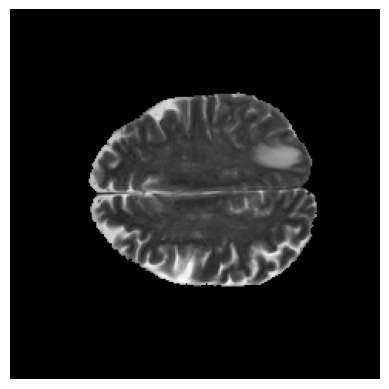

In [11]:
image.shape
plt.imshow(image[:,:,3], cmap='gray')
plt.axis('off')
plt.show()

In [12]:
mask = f['mask']

In [13]:
mask.shape

(240, 240, 3)

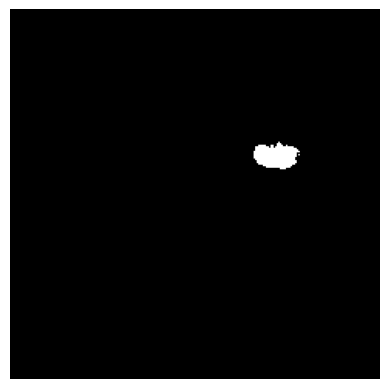

In [14]:
plt.imshow(mask[:,:,1], cmap='gray')
plt.axis('off')
plt.show()

In [15]:
data_df['volume'].nunique()

369

In [16]:
gss_1 = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=42)
train_idx, temp_idx = next(gss_1.split(data_df, groups=data_df["volume"]))

train_df = data_df.iloc[train_idx]
temp_df = data_df.iloc[temp_idx]

gss_2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=42)
val_idx, test_idx = next(gss_2.split(temp_df, groups=temp_df["volume"]))

val_df = temp_df.iloc[val_idx]
test_df = temp_df.iloc[test_idx]

train_df['volume'].nunique(), val_df['volume'].nunique(), test_df['volume'].nunique()

(258, 55, 56)

In [17]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15)
])

In [18]:
class CustomImageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        volume_id = self.df.iloc[idx]["volume"]
        slice_id = self.df.iloc[idx]["slice"]
        file_path = f'/content/brats2020-training-data/BraTS2020_training_data/content/data/volume_{volume_id}_slice_{slice_id}.h5'

        with h5.File(file_path, 'r') as f:
          image_np = f['image'][:]
          mask_np = f['mask'][:]

        image_tensor = torch.from_numpy(image_np).permute(2, 0, 1).float()
        mask_tensor = torch.from_numpy(mask_np).permute(2, 0, 1).float()
        image_tensor = (image_tensor - image_tensor.mean()) / (image_tensor.std() + 1e-6)
        if self.transform:
            image = self.transform(image_tensor)
            mask = self.transform(mask_tensor)

        # print(f"Loading file: {file_path}")
        # print(f"image_np shape: {image_np.shape}, mask_np shape: {mask_np.shape}")
        # print(f"mask_np unique values: {np.unique(mask_np)}")
        return image_tensor, mask_tensor

In [19]:
train_dataset = CustomImageDataset(train_df, transform=transform)
val_dataset = CustomImageDataset(val_df, transform=transform)
test_dataset = CustomImageDataset(test_df, transform=transform)

In [37]:
BATCH_SIZE = 16
EPOCHS = 18

In [21]:
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers = 2, pin_memory=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers = 2, pin_memory=True)
test_dataloader = DataLoader(test_dataset, batch_size = BATCH_SIZE, shuffle=True, num_workers = 2, pin_memory=True)

In [22]:
class UNet(nn.Module):
    def __init__(self, n_class):
        super().__init__()
        self.e11 = nn.Conv2d(4, 64, kernel_size=3, padding=1)
        self.e12 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)


        self.e21 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.e22 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)


        self.e31 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.e32 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)


        self.e41 = nn.Conv2d(256, 512, kernel_size=3, padding=1)
        self.e42 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)


        self.e51 = nn.Conv2d(512, 1024, kernel_size=3, padding=1)
        self.e52 = nn.Conv2d(1024, 1024, kernel_size=3, padding=1)



        self.upconv1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.d11 = nn.Conv2d(1024, 512, kernel_size=3, padding=1)
        self.d12 = nn.Conv2d(512, 512, kernel_size=3, padding=1)

        self.upconv2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.d21 = nn.Conv2d(512, 256, kernel_size=3, padding=1)
        self.d22 = nn.Conv2d(256, 256, kernel_size=3, padding=1)

        self.upconv3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.d31 = nn.Conv2d(256, 128, kernel_size=3, padding=1)
        self.d32 = nn.Conv2d(128, 128, kernel_size=3, padding=1)

        self.upconv4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.d41 = nn.Conv2d(128, 64, kernel_size=3, padding=1)
        self.d42 = nn.Conv2d(64, 64, kernel_size=3, padding=1)

        self.relu = nn.ReLU()


        self.outconv = nn.Conv2d(64, n_class, kernel_size=1)

    def forward(self, x):
        xe11 = self.relu(self.e11(x))
        xe12 = self.relu(self.e12(xe11))
        xp1 = self.pool1(xe12)

        xe21 = self.relu(self.e21(xp1))
        xe22 = self.relu(self.e22(xe21))
        xp2 = self.pool2(xe22)

        xe31 = self.relu(self.e31(xp2))
        xe32 = self.relu(self.e32(xe31))
        xp3 = self.pool3(xe32)

        xe41 = self.relu(self.e41(xp3))
        xe42 = self.relu(self.e42(xe41))
        xp4 = self.pool4(xe42)

        xe51 = self.relu(self.e51(xp4))
        xe52 = self.relu(self.e52(xe51))

        xu1 = self.upconv1(xe52)
        xu11 = torch.cat([xu1, xe42], dim=1)
        xd11 = self.relu(self.d11(xu11))
        xd12 = self.relu(self.d12(xd11))

        xu2 = self.upconv2(xd12)
        xu22 = torch.cat([xu2, xe32], dim=1)
        xd21 = self.relu(self.d21(xu22))
        xd22 = self.relu(self.d22(xd21))

        xu3 = self.upconv3(xd22)
        xu33 = torch.cat([xu3, xe22], dim=1)
        xd31 = self.relu(self.d31(xu33))
        xd32 = self.relu(self.d32(xd31))

        xu4 = self.upconv4(xd32)
        xu44 = torch.cat([xu4, xe12], dim=1)
        xd41 = self.relu(self.d41(xu44))
        xd42 = self.relu(self.d42(xd41))

        out = self.outconv(xd42)

        return out

In [23]:
model = UNet(n_class = 3)
model.to(Device)

UNet(
  (e11): Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (e12): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (e21): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (e22): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (e31): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (e32): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (e41): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (e42): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (e51): Conv2d(512, 1024, kernel_size=(

In [24]:
def dice_loss(pred, target, smooth=1e-6):

    pred = torch.sigmoid(pred)

    num_classes = pred.shape[1]

    dice = 0

    for c in range(num_classes):

        pred_c = pred[:, c]
        target_c = target[:, c]

        intersection = (pred_c * target_c).sum(dim=(1,2))

        union = pred_c.sum(dim=(1,2)) + target_c.sum(dim=(1,2))

        dice += (2 * intersection + smooth) / (union + smooth)

    return 1 - dice.mean() / num_classes

In [25]:
optimier = Adam(model.parameters(), lr=0.0001)
bce_loss = nn.BCEWithLogitsLoss()
total_train_loss = []
total_val_loss = []
total_train_acc = []
total_val_acc = []


In [40]:
checkpoint = torch.load(
    '/content/drive/MyDrive/brats_checkpoint.pth',
    map_location=Device
)
model.load_state_dict(checkpoint['model_state_dict'])

optimier.load_state_dict(checkpoint['optimizer_state_dict'])

start_epoch = checkpoint['epoch'] + 1

total_train_loss = checkpoint['train_loss']
total_val_loss = checkpoint['val_loss']

total_train_acc = checkpoint['train_dice']
total_val_acc = checkpoint['val_dice']



for epoch in range(start_epoch, EPOCHS):
    start = time.time()
    train_loss = 0
    val_loss = 0
    train_acc = 0
    val_acc = 0
    model.train()
    for image, mask in train_dataloader :

      image = image.to(Device)
      mask = mask.to(Device)
      optimier.zero_grad()
      outputs = model(image)
      #if epoch == start_epoch: # Print for the first batch of the first epoch
          #print(f"Outputs shape: {outputs.shape}, Mask shape: {mask.shape}")
          # print(f"Outputs (sigmoid) min: {torch.sigmoid(outputs).min()}, max: {torch.sigmoid(outputs).max()}")
          # print(f"Mask min: {mask.min()}, max: {mask.max()}, unique: {torch.unique(mask)}")
      losst1 = dice_loss(outputs, mask)
      losst2 = bce_loss(outputs, mask)
      loss = losst1 + losst2
      train_loss += loss.item()
      train_acc += (1 - losst1.item())
      loss.backward()
      optimier.step()


    model.eval()
    with torch.inference_mode() :
      for image, mask in val_dataloader :
        image = image.to(Device)
        mask = mask.to(Device)
        output = model(image)
        lossv1 = dice_loss(output, mask)
        lossv2 = bce_loss(output, mask)
        loss = lossv1 + lossv2
        val_loss += loss.item()
        val_acc += (1 - lossv1.item())

    total_train_loss.append(round(train_loss / len(train_dataloader), 4))
    total_val_loss.append(round(val_loss / len(val_dataloader), 4))
    total_train_acc.append(round(train_acc / len(train_dataloader), 4))
    total_val_acc.append(round(val_acc / len(val_dataloader), 4))

    end = time.time()

    print({"epoch": epoch},
   {"train_loss": round(train_loss / len(train_dataloader), 4)},
  {"val_loss": round(val_loss / len(val_dataloader), 4)},
  {"train_acc": round(train_acc / len(train_dataloader), 4)},
   {"val_acc": round(val_acc / len(val_dataloader), 4)},
    {"time_taken": round(end - start, 4)})

    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimier.state_dict(),
        'train_loss': total_train_loss,
        'val_loss': total_val_loss,
        'train_dice': total_train_acc,
        'val_dice': total_val_acc
    }, '/content/drive/MyDrive/brats_checkpoint.pth')

In [35]:
test_loss = 0
test_acc = 0
model.eval()
with torch.inference_mode() :
  for image, mask in test_dataloader :
    image = image.to(Device)
    mask = mask.to(Device)
    outputs = model(image)
    lossv1 = dice_loss(outputs, mask)
    loss2 = bce_loss(outputs, mask)
    loss = lossv1 + loss2
    test_loss += loss.item()
    test_acc += (1 - lossv1.item())

print(f"Test Loss: {round(test_loss / len(test_dataloader), 4)}, Test Dice Score: {round(test_acc / len(test_dataloader), 4)}")

Test Loss: 0.2092, Test Dice Score: 0.8214


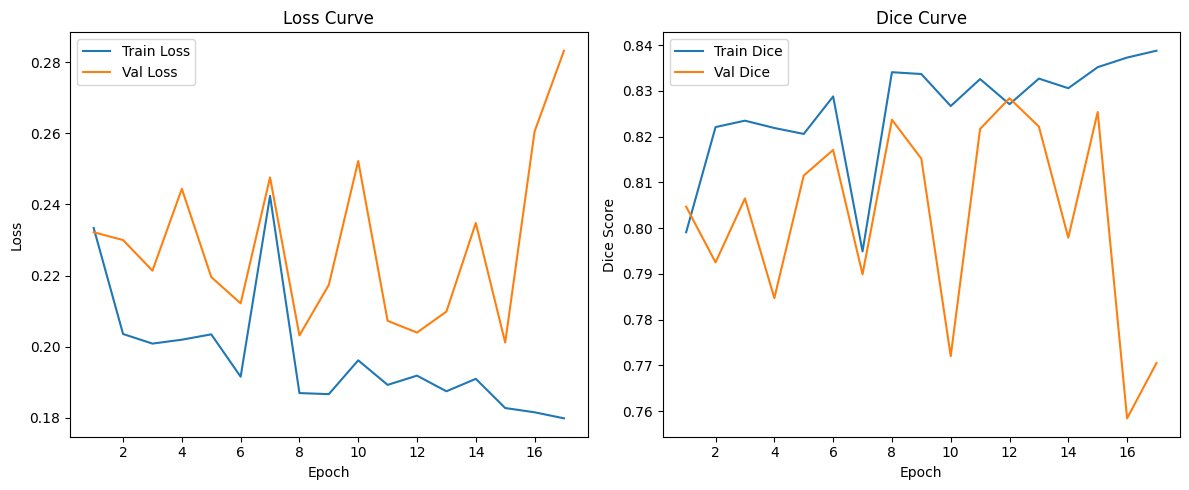

In [29]:
def plot_metrics(train_loss, val_loss, train_acc, val_acc):

    epochs = range(1, len(train_loss) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label='Train Loss')
    plt.plot(epochs, val_loss, label='Val Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Loss Curve')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_acc, label='Train Dice')
    plt.plot(epochs, val_acc, label='Val Dice')
    plt.xlabel('Epoch')
    plt.ylabel('Dice Score')
    plt.title('Dice Curve')
    plt.legend()

    plt.tight_layout()
    plt.show()

start = 21

plot_metrics(
    total_train_loss[start:],
    total_val_loss[start:],
    total_train_acc[start:],
    total_val_acc[start:]
)

Best Dice Score: 0.9867


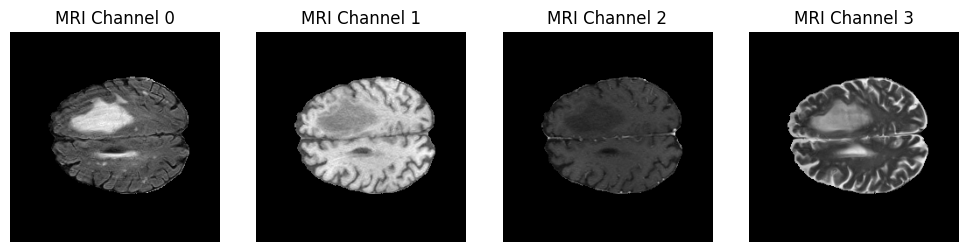

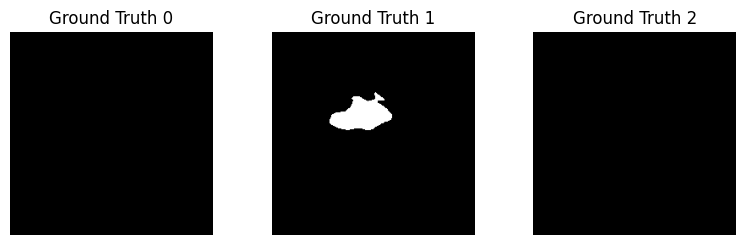

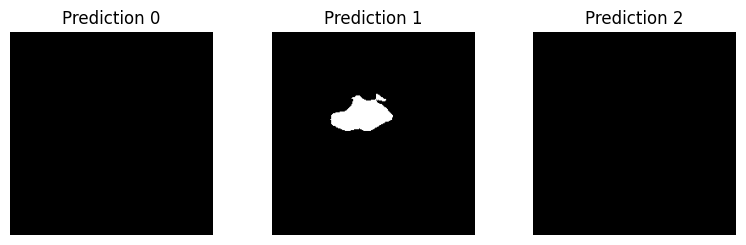

In [41]:
def show_best_sample(model, dataset, device, dice_loss_fn):

    model.eval()

    best_dice = -1
    best_image = None
    best_mask = None
    best_pred = None

    with torch.no_grad():

        for image, mask in dataset:


            if mask.sum() == 0:
                continue

            image_batch = image.unsqueeze(0).to(device)
            mask_batch = mask.unsqueeze(0).to(device)

            output = model(image_batch)

            pred = (torch.sigmoid(output) > 0.5).float()

            dice_score = 1 - dice_loss_fn(output, mask_batch).item()

            if dice_score > best_dice:
                best_dice = dice_score
                best_image = image.cpu()
                best_mask = mask.cpu()
                best_pred = pred.squeeze(0).cpu()

    print(f"Best Dice Score: {best_dice:.4f}")


    plt.figure(figsize=(10, 2.5))

    for i in range(4):
        plt.subplot(1, 4, i + 1)
        plt.imshow(best_image[i].numpy(), cmap="gray")
        plt.title(f"MRI Channel {i}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(8, 2.5))

    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(best_mask[i].numpy(), cmap="gray")
        plt.title(f"Ground Truth {i}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(8, 2.5))

    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(best_pred[i].numpy(), cmap="gray")
        plt.title(f"Prediction {i}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()



show_best_sample(
    model=model,
    dataset=test_dataset,
    device=Device,
    dice_loss_fn=dice_loss
)

Worst Dice Score: 0.0000


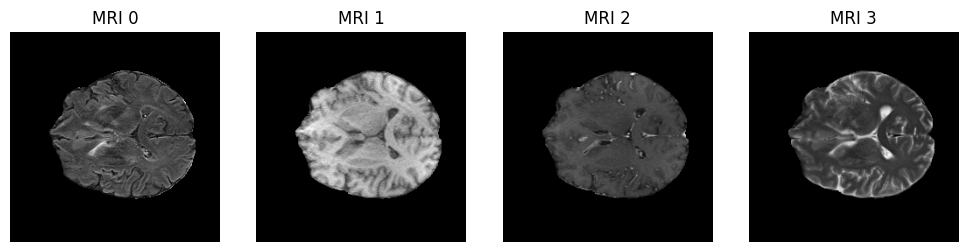

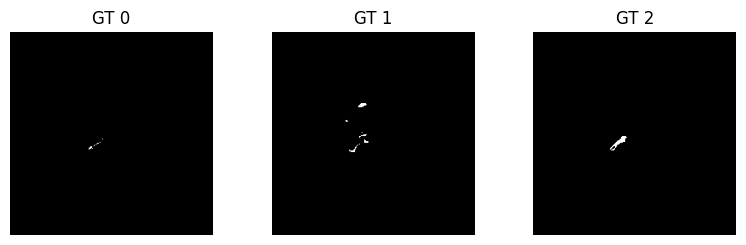

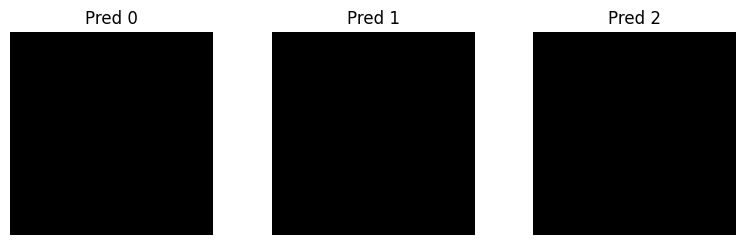

In [43]:
def show_worst_sample(model, dataset, device, dice_loss_fn):

    model.eval()

    worst_dice = float('inf')
    worst_image = None
    worst_mask = None
    worst_pred = None

    with torch.no_grad():

        for image, mask in dataset:


            if mask.sum() == 0:
                continue

            image_batch = image.unsqueeze(0).to(device)
            mask_batch = mask.unsqueeze(0).to(device)

            output = model(image_batch)

            pred = (torch.sigmoid(output) > 0.5).float()

            dice_score = 1 - dice_loss_fn(output, mask_batch).item()

            if dice_score < worst_dice:
                worst_dice = dice_score
                worst_image = image.cpu()
                worst_mask = mask.cpu()
                worst_pred = pred.squeeze(0).cpu()

    print(f"Worst Dice Score: {worst_dice:.4f}")


    plt.figure(figsize=(10, 2.5))
    for i in range(4):
        plt.subplot(1, 4, i + 1)
        plt.imshow(worst_image[i].numpy(), cmap="gray")
        plt.title(f"MRI {i}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(8, 2.5))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(worst_mask[i].numpy(), cmap="gray")
        plt.title(f"GT {i}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(8, 2.5))
    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(worst_pred[i].numpy(), cmap="gray")
        plt.title(f"Pred {i}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


show_worst_sample(
    model=model,
    dataset=test_dataset,
    device=Device,
    dice_loss_fn=dice_loss
)